## Comparative Analysis of Linear Regression and Regularization Techniques Using Lung Adenocarcinoma Gene-Expression Data



### 1. Project Objective

To compare the performance of Linear Regression, Lasso Regression (L1 regularization), Ridge Regression (L2 regularization), and Elastic Net Regression on the GSE31210 lung adenocarcinoma (LUAD) gene-expression dataset.

The project explores how regularization influences predictive performance, model complexity, and coefficient shrinkage when working with high-dimensional biological data. It also examines how Lasso and Elastic Net influence feature selection and model sparsity.

Model performance is evaluated using Mean Squared Error (MSE) and R² on an independent test set, with cross-validation used for hyperparameter selection.

_**Disclaimer:** The primary purpose of this project is to gain practical experience with regression and regularization techniques using a real-world biological dataset. It is an ML methodology exercise rather than an attempt to answer a specific biological research question or draw clinically meaningful conclusions._


### 2. Import Libraries

Import the Python libraries required for data loading, manipulation, exploratory analysis, preprocessing, model development, hyperparameter tuning, and performance evaluation.

In [30]:
import gzip
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.metrics import mean_squared_error, r2_score

### 3. Load and Inspect the Dataset

Load the prepared gene-expression matrix and inspect its dimensions, column names, and overall structure.

Each row represents a tumour sample, while each column represents an Affymetrix probe measuring gene-expression levels.

The dataset is inspected to verify its structure, identify missing values, check for duplicate feature names, and ensure that clinical metadata, sample identifiers, and control probes are not inadvertently included as predictive features.

In [31]:
# Load the prepared gene-expression dataset


file_path = "./geo_cache/GSE31210_series_matrix.gz"

# Locate the beginning and end of the expression table
with gzip.open(file_path, "rt") as f:
    lines = f.readlines()

start = next(
    i for i, line in enumerate(lines)
    if line.startswith("!series_matrix_table_begin")
) + 1

end = next(
    i for i, line in enumerate(lines)
    if line.startswith("!series_matrix_table_end")
)

# Read the tab-separated expression matrix
from io import StringIO

expression_df = pd.read_csv(
    StringIO("".join(lines[start:end])),
    sep="\t",
    index_col=0
)

print("Expression matrix dimensions:", expression_df.shape)
display(expression_df.head())

#Let's transpose the matrix
df = expression_df.T

print("Rows (samples):", df.shape[0])
print("Columns (features):", df.shape[1])

display(df.head())

# Check sample identifiers
print("Sample IDs:")
print(df.index[:10].tolist())

# Check feature names
print("\nFirst 20 feature names:")
print(df.columns[:20].tolist())

# Count Affymetrix control probes
control_probes = df.columns.astype(str).str.startswith("AFFX-")
print("\nNumber of AFFX control probes:", control_probes.sum())

# Check missing values
print("Total missing values:", df.isna().sum().sum())

# Check duplicate column names
print("Duplicate feature names:", df.columns.duplicated().sum())

Expression matrix dimensions: (54675, 246)


,GSM773540,GSM773541,GSM773542,GSM773543,GSM773544,GSM773545,GSM773546,GSM773547,GSM773548,GSM773549,...,GSM773776,GSM773777,GSM773778,GSM773779,GSM773780,GSM773781,GSM773782,GSM773783,GSM773784,GSM773785
ID_REF,,,,,,,,,,,,,,,,,,,,,
1007_s_at,2955.72500,2278.312200,2789.68400,2517.980600,1659.793000,3031.719000,3128.152600,2055.748200,1962.671000,2740.99700,...,1365.309900,843.480900,1476.467300,1513.347700,1195.83500,1214.154400,1330.266000,900.721700,2301.615700,1476.738900
1053_at,316.62130,496.103900,460.94750,493.378400,283.422300,378.949000,489.952000,435.698000,361.991100,387.05680,...,292.113500,275.213900,264.432900,202.759800,241.82290,245.767500,228.989400,178.586100,327.822400,277.205900
117_at,334.93470,359.712800,289.45830,362.904000,295.593700,199.535700,364.205800,221.348300,225.627600,382.45050,...,253.960960,201.920560,222.478810,1384.393060,255.63780,1504.654770,388.454720,6605.689120,301.709620,162.603730
121_at,300.46610,697.613700,491.83220,287.804400,197.953400,226.258800,422.496700,336.385800,222.987400,530.52240,...,410.368600,439.301200,390.460500,473.879500,374.90280,303.306500,499.234000,445.086300,414.621900,479.670100
1255_g_at,38.15729,6.803992,23.51804,7.853021,15.531381,1.445248,26.420893,50.256579,18.041223,14.14336,...,4.097409,15.008199,3.619681,3.532373,3.23697,11.297682,3.026853,21.656752,3.875111,4.266732


Rows (samples): 246
Columns (features): 54675


ID_REF,1007_s_at,1053_at,117_at,121_at,1255_g_at,1294_at,1316_at,1320_at,1405_i_at,1431_at,...,AFFX-r2-Ec-bioD-3_at,AFFX-r2-Ec-bioD-5_at,AFFX-r2-P1-cre-3_at,AFFX-r2-P1-cre-5_at,AFFX-ThrX-3_at,AFFX-ThrX-5_at,AFFX-ThrX-M_at,AFFX-TrpnX-3_at,AFFX-TrpnX-5_at,AFFX-TrpnX-M_at
GSM773540,2955.7250,316.6213,334.9347,300.4661,38.157290,1260.4731,240.06010,56.575418,577.6273,65.06958,...,12173.303,11520.929,33036.91,25718.62,2742.8541,165.23719,803.1562,25.143148,41.637265,4.349705
GSM773541,2278.3122,496.1039,359.7128,697.6137,6.803992,591.0589,236.70260,46.161304,1150.2953,21.36367,...,7829.373,7186.855,21293.98,16558.21,991.8196,55.52896,279.7559,2.008132,20.558889,3.349300
GSM773542,2789.6840,460.9475,289.4583,491.8322,23.518040,1203.4293,128.06689,48.076497,354.9501,4.63179,...,9097.154,7925.071,23816.05,19100.51,1346.9263,60.69537,433.7939,1.371186,17.900243,1.473170
GSM773543,2517.9806,493.3784,362.9040,287.8044,7.853021,777.7997,156.00560,49.861631,686.5361,24.95041,...,7854.235,7480.969,21272.02,16335.57,1222.7936,63.41651,328.8829,4.401906,23.116128,3.022770
GSM773544,1659.7930,283.4223,295.5937,197.9534,15.531381,895.7807,139.51249,36.539611,463.9925,23.79848,...,9437.347,8723.881,24296.58,19187.24,2006.4175,130.02677,635.2294,3.187128,6.959399,6.067641


Sample IDs:
['GSM773540', 'GSM773541', 'GSM773542', 'GSM773543', 'GSM773544', 'GSM773545', 'GSM773546', 'GSM773547', 'GSM773548', 'GSM773549']

First 20 feature names:
['1007_s_at', '1053_at', '117_at', '121_at', '1255_g_at', '1294_at', '1316_at', '1320_at', '1405_i_at', '1431_at', '1438_at', '1487_at', '1494_f_at', '1552256_a_at', '1552257_a_at', '1552258_at', '1552261_at', '1552263_at', '1552264_a_at', '1552266_at']

Number of AFFX control probes: 62
Total missing values: 0
Duplicate feature names: 0


### 4. Remove Control Probes

Remove Affymetrix control probes whose IDs begin with `AFFX-`. These probes are used for assay quality control and normalization rather than representing ordinary biological expression features.

Removing them ensures that the predictive feature matrix contains biological expression probes only.

In [32]:
# Identify and remove Affymetrix control probes
control_probes = df.columns.astype(str).str.startswith("AFFX-")

df_filtered = df.loc[:, ~control_probes].copy()

print("Original dimensions:", df.shape)
print("Dimensions after removing control probes:", df_filtered.shape)



Original dimensions: (246, 54675)
Dimensions after removing control probes: (246, 54613)


### 5. Select a target for the regression comparison

For this ML exercise, we will predict the expression level of one probe using the expression levels of the remaining features. This provides a continuous target suitable for comparing Linear Regression, Lasso, Ridge, and Elastic Net.



In [33]:

# Calculate variance for each expression probe
probe_variances = df_filtered.var(axis=0)

# Display the 10 probes with the highest variance
top_variance_probes = probe_variances.nlargest(10)

display(top_variance_probes)



ID_REF
218835_at      1.172316e+08
214387_x_at    1.126617e+08
224588_at      1.089104e+08
205982_x_at    1.027123e+08
215946_x_at    1.021826e+08
211735_x_at    1.008938e+08
215121_x_at    9.530875e+07
226147_s_at    8.817519e+07
211657_at      8.353694e+07
38691_s_at     8.127580e+07
dtype: float64

In [34]:
print("Target probe variance:", probe_variances["218835_at"])
print("Highest variance:", probe_variances.max())
print("Highest variance probe:", probe_variances.idxmax())



Target probe variance: 117231645.963627
Highest variance: 117231645.963627
Highest variance probe: 218835_at


#### _Target Selection Justification_
Probe 218835_at was selected because it exhibited the highest expression variance across the samples. Its GPL570 annotation maps to SFTPA1 /// SFTPA2, so it cannot be uniquely assigned to either gene.

The target variable is defined before model development and excluded from the predictor features. This ensures that the target expression values are not inadvertently included among the model inputs.

In [36]:
target_probe = "218835_at"

# Define target and predictors
y = df_filtered[target_probe]
X = df_filtered.drop(columns=[target_probe])

print("Target probe:", target_probe)
print("Target shape:", y.shape)
print("Predictor matrix shape:", X.shape)

Target probe: 218835_at
Target shape: (246,)
Predictor matrix shape: (246, 54612)


### 6. Split the Data into Training and Test Sets

The dataset is divided into training and test sets. The training data will be used to fit the models and select regularization parameters through cross-validation. The test data will be kept separate and used for final performance evaluation.

In [37]:
# Split the dataset into training and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

# Display the number of samples in each set
print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

# Display the dimensions of the resulting datasets
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)

Training samples: 196
Test samples: 50
X_train shape: (196, 54612)
X_test shape: (50, 54612)
y_train shape: (196,)
y_test shape: (50,)


In [38]:
# Select the top 1,000 variable probes using training data only

probe_variances = X_train.var(axis=0)

top_probes = probe_variances.nlargest(1000).index

# Apply the same selected probes to training and test data
X_train_filtered = X_train[top_probes]
X_test_filtered = X_test[top_probes]

print("Training features:", X_train_filtered.shape)
print("Test features:", X_test_filtered.shape)

Training features: (196, 1000)
Test features: (50, 1000)


To reduce the dimensionality of the dataset, the 1,000 predictor probes with the highest variance are selected using the training data only. The same set of probes is then retained in the test data.

### 7. Feature Selection and Standardization

The selected predictor features are standardized so that they have comparable scales. This is particularly important for Lasso, Ridge, and Elastic Net because regularization penalizes coefficient magnitudes.

The scaler is fitted using the training data only and then applied to the test data, preventing information from the test set from influencing the scaling process.

In [39]:
# Initialize the scaler
scaler = StandardScaler()

# Fit on training data and transform both datasets
X_train_scaled = scaler.fit_transform(X_train_filtered)
X_test_scaled = scaler.transform(X_test_filtered)

### 8. Train the Regression Models

Four regression models are trained using the same training data:
- Linear Regression: Serves as the baseline model without regularization.
- Lasso Regression: Applies $L1$ regularization, which can shrink some coefficients to exactly zero.
- Ridge Regression: Applies $L2$ regularization, which shrinks coefficient magnitudes but generally does not reduce them to exactly zero.
- Elastic Net Regression: Combines $L1$ and $L2$ regularization.
Cross-validation is used to select the regularization parameters for Lasso, Ridge, and Elastic Net. The trained models are subsequently evaluated using the independent test set.



In [40]:
from sklearn.linear_model import (
    ElasticNetCV,
    LassoCV,
    LinearRegression,
    RidgeCV,
)

# Set the number of cross-validation folds
cv_folds = 5

# 1. Linear Regression
print("Training Linear Regression...")
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train)

# 2. Lasso Regression (L1)
print("Training Lasso Regression with 5-fold CV...")
lasso_model = LassoCV(
    cv=cv_folds,
    random_state=42,
    max_iter=5000
)
lasso_model.fit(X_train_scaled, y_train)

# 3. Ridge Regression (L2)
print("Training Ridge Regression with 5-fold CV...")
ridge_model = RidgeCV(
    alphas=np.logspace(-3, 3, 50),
    cv=cv_folds
)
ridge_model.fit(X_train_scaled, y_train)

# 4. Elastic Net Regression
print("Training Elastic Net Regression with 5-fold CV...")
elastic_model = ElasticNetCV(
    cv=cv_folds,
    l1_ratio=[0.2, 0.5, 0.8],
    random_state=42,
    max_iter=5000
)
elastic_model.fit(X_train_scaled, y_train)

print("All models trained successfully!")

Training Linear Regression...
Training Lasso Regression with 5-fold CV...
Training Ridge Regression with 5-fold CV...
Training Elastic Net Regression with 5-fold CV...
All models trained successfully!


### 9. Inspect Regularization Parameters
After training the models, the selected regularization parameters are examined to understand how cross-validation tuned the Lasso, Ridge, and Elastic Net models.

The number of non-zero coefficients is also compared across the regularized models to examine how each regularization technique influences feature selection and model sparsity.

In [41]:
print("REGULARIZATION PARAMETERS")
print("-" * 40)

print("Lasso alpha:", lasso_model.alpha_)
print("Ridge alpha:", ridge_model.alpha_)
print("Elastic Net alpha:", elastic_model.alpha_)
print("Elastic Net l1_ratio:", elastic_model.l1_ratio_)

print("\nNON-ZERO COEFFICIENTS")
print("-" * 40)

print("Linear Regression:", np.count_nonzero(linear_model.coef_))
print("Lasso:", np.count_nonzero(lasso_model.coef_))
print("Ridge:", np.count_nonzero(ridge_model.coef_))
print("Elastic Net:", np.count_nonzero(elastic_model.coef_))

REGULARIZATION PARAMETERS
----------------------------------------
Lasso alpha: 340.2149149528742
Ridge alpha: 244.205309454865
Elastic Net alpha: 8.544637938602191
Elastic Net l1_ratio: 0.8

NON-ZERO COEFFICIENTS
----------------------------------------
Linear Regression: 1000
Lasso: 74
Ridge: 1000
Elastic Net: 964


#### _Regularization Parameter Analysis_

- The selected regularization parameters differed between the models.

- Lasso selected an alpha value of approximately 340.21 and retained 74 non-zero coefficients out of 1,000 predictors.

- Ridge selected an alpha value of approximately 244.21 and retained all 1,000 coefficients, although regularization shrinks their magnitudes.

- Elastic Net selected an alpha value of approximately 8.54, with an $L1$ ratio of 0.8, and retained 964 non-zero coefficients.

- Although all three methods apply regularization, they produced different levels of coefficient sparsity. Lasso produced the sparsest model, while Elastic Net retained most of the predictors. Ridge retained all coefficients.

- These results illustrate how the choice of regularization method and its selected hyperparameters can influence coefficient shrinkage and model complexity.

### 10. Evaluate Model Performance
The four trained regression models are evaluated on the held-out test set using Mean Squared Error (MSE) and the coefficient of determination (R²).
- **MSE:** Measures the average squared difference between actual and predicted expression values. Lower values indicate better predictive performance.
- **R²:** Measures how much variation in the target variable is explained by the model relative to a mean-prediction baseline. Higher values generally indicate better performance. A negative test R² is also possible.

All four models are evaluated using the same test samples to ensure a consistent comparison. The number of non-zero coefficients is also reported to examine model sparsity.


In [42]:
models = {
    "Linear Regression": linear_model,
    "Lasso (L1)": lasso_model,
    "Ridge (L2)": ridge_model,
    "Elastic Net": elastic_model,
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test_scaled)

    mse = mean_squared_error(y_test, predictions)
    r2 = r2_score(y_test, predictions)

    n_nonzero = np.count_nonzero(model.coef_)

    results.append(
        {
            "Model": name,
            "Non-Zero Coefficients": n_nonzero,
            "Test MSE": mse,
            "Test R²": r2,
        }
    )

results_df = pd.DataFrame(results)

display(results_df.sort_values("Test MSE").round(4))

,Model,Non-Zero Coefficients,Test MSE,Test R²
2,Ridge (L2),1000,8.571923e+07,0.4225
3,Elastic Net,964,8.613904e+07,0.4197
1,Lasso (L1),74,9.121291e+07,0.3855
0,Linear Regression,1000,9.204392e+07,0.3799


#### _Model Performance Comparison_

Ridge Regression achieved the best predictive performance on the test set, with an MSE of approximately 8.57 × 10⁷ and an R² of 0.4225. Elastic Net performed very similarly, with an R² of 0.4197.

Lasso retained only 74 non-zero coefficients out of 1,000 predictors, producing a much sparser model, although its predictive performance was lower than Ridge and Elastic Net. Linear Regression had the highest test MSE and lowest R² among the four models.

These results illustrate a trade-off between predictive performance and model sparsity. In this particular dataset and train-test split, Ridge provided the best predictive performance, while Lasso produced the most compact model.

### 11. Model Visualization and Interpretation

**11.1. Actual vs. Predicted Expression Plots:** These plots compare predicted expression values against actual values in the held-out test set. The diagonal reference line represents perfect predictions. The distance of points from this line provides a visual indication of prediction errors.

**11.2. Prediction Summary:** The mean, standard deviation, and correlation between actual and predicted values are compared across models to examine their prediction patterns and variability.

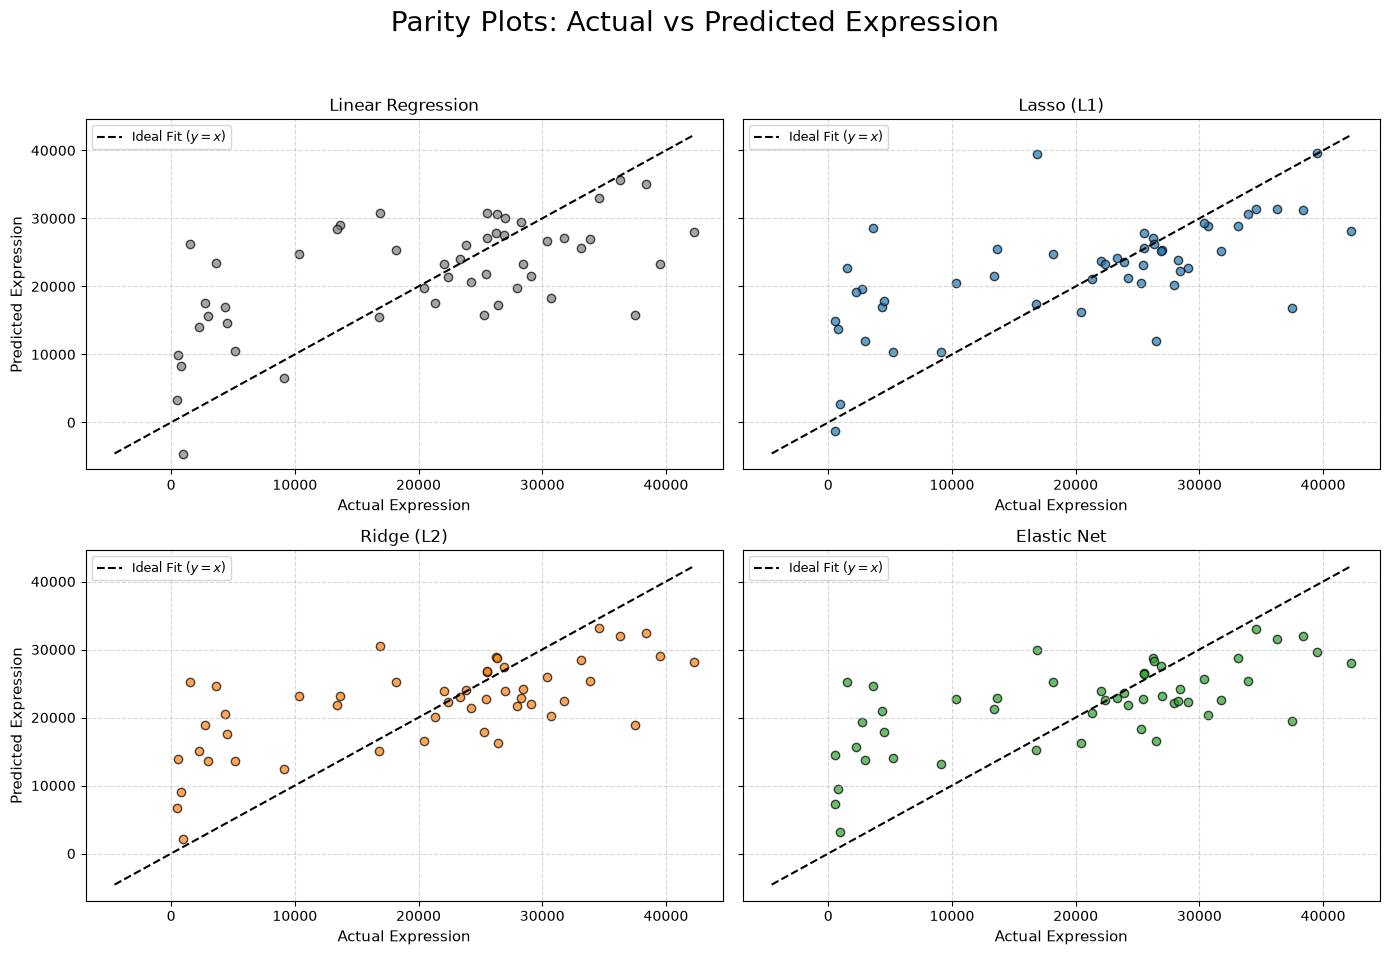

In [43]:
import matplotlib.pyplot as plt

predictions_dict = {
    "Linear Regression": linear_model.predict(X_test_scaled),
    "Lasso (L1)": lasso_model.predict(X_test_scaled),
    "Ridge (L2)": ridge_model.predict(X_test_scaled),
    "Elastic Net": elastic_model.predict(X_test_scaled),
}

fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
axes = axes.flatten()
fig.suptitle("Parity Plots: Actual vs Predicted Expression", fontsize=20)

colors = ["#7f7f7f", "#1f77b4", "#ff7f0e", "#2ca02c"]
all_vals = np.concatenate([y_test] + list(predictions_dict.values()))
min_v, max_v = all_vals.min(), all_vals.max()
x_line = np.linspace(min_v, max_v, 100)

for i, (name, y_pred) in enumerate(predictions_dict.items()):
    ax = axes[i]
    ax.plot(
        x_line, x_line, color="black", linestyle="--", label="Ideal Fit ($y=x$)"
    )
    ax.scatter(y_test, y_pred, alpha=0.7, color=colors[i], edgecolors="k")
    ax.set_title(name, fontsize=12)
    ax.set_xlabel("Actual Expression", fontsize=11)
    if i in [0, 2]:
        ax.set_ylabel("Predicted Expression", fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="upper left", fontsize=9)

plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()




In [44]:
prediction_summary = []

for name, model in models.items():
    y_pred = model.predict(X_test_scaled)

    correlation = np.corrcoef(y_test, y_pred)[0, 1]

    prediction_summary.append({
        "Model": name,
        "Actual Mean": y_test.mean(),
        "Predicted Mean": y_pred.mean(),
        "Correlation": correlation,
        "Actual SD": y_test.std(),
        "Predicted SD": y_pred.std()
    })

prediction_df = pd.DataFrame(prediction_summary)
display(prediction_df.round(3))

,Model,Actual Mean,Predicted Mean,Correlation,Actual SD,Predicted SD
0,Linear Regression,20455.315,21751.064,0.627,12306.794,8179.212
1,Lasso (L1),20455.315,22278.271,0.639,12306.794,7745.021
2,Ridge (L2),20455.315,21794.057,0.674,12306.794,6478.655
3,Elastic Net,20455.315,21883.736,0.680,12306.794,6214.229


#### _Prediction Analysis_
The correlation between actual and predicted expression values was highest for Elastic Net (0.680), followed closely by Ridge (0.674), Lasso (0.639), and Linear Regression (0.627).

All four models produced lower standard deviations for predicted values than for actual values, indicating that their predictions were less variable than the observed expression values.

The predicted means were also somewhat higher than the actual mean across all four models.

Although Elastic Net had the highest correlation, Ridge achieved the best MSE and R² in the test-set evaluation. This illustrates that different performance measures capture different aspects of model predictions.

**11.3 Feature Coefficient Distributions (Sparsity Comparison):** Histograms on a log density scale displaying the distribution of active coefficient values. These visualize model complexity and highlight the extreme sparsity achieved by Lasso ($L_1$) compared to the dense shrinkage of Ridge ($L_2$) and Elastic Net.

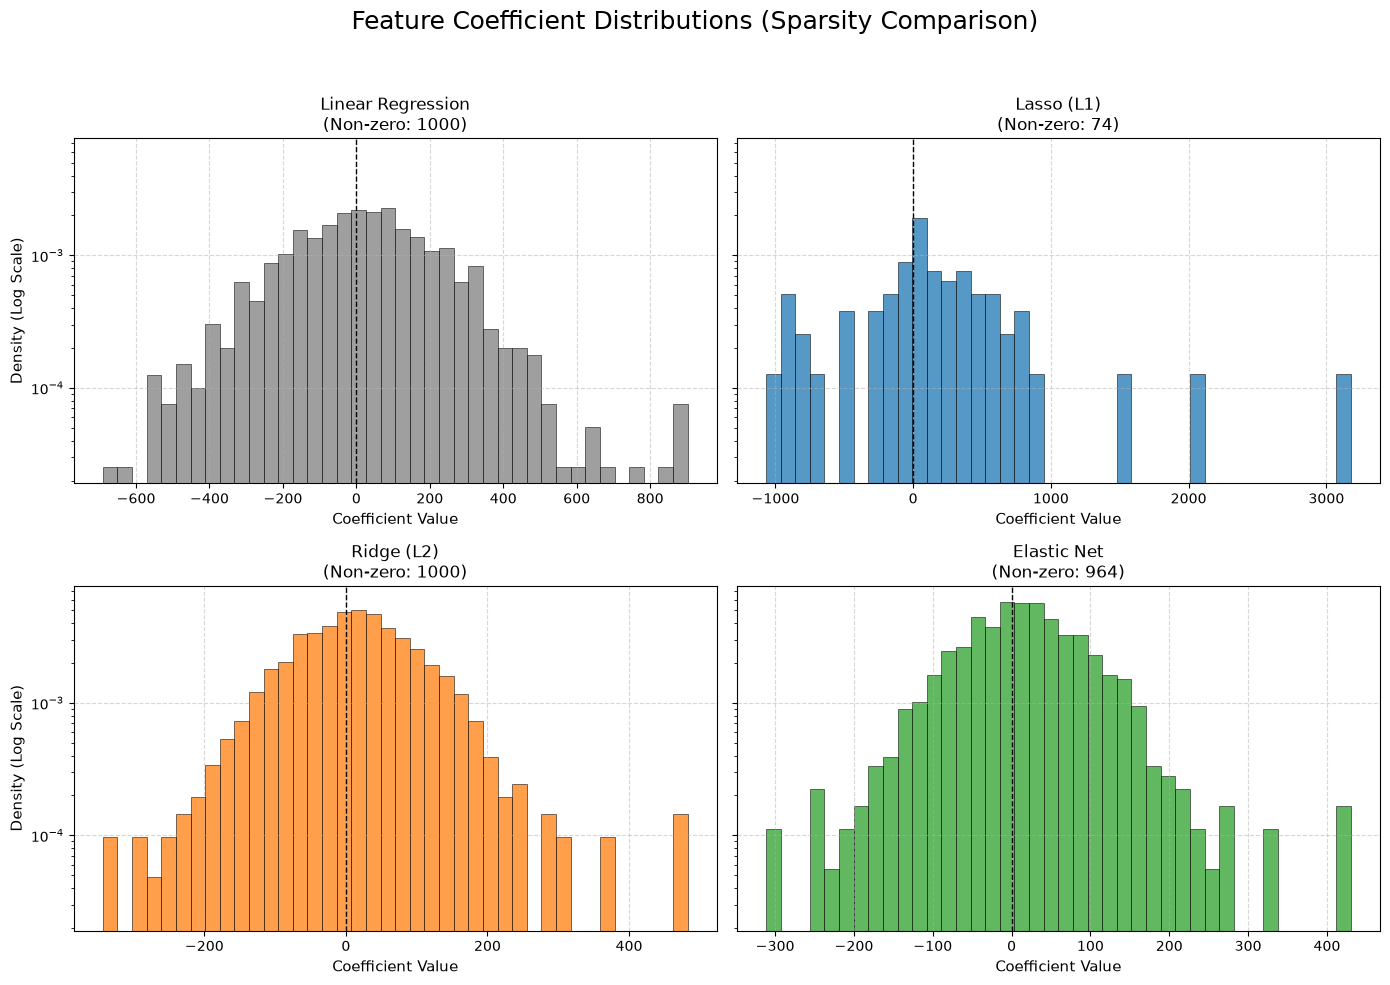

In [45]:
import matplotlib.pyplot as plt

# Create a 2 × 2 layout
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
axes = axes.flatten()

fig.suptitle(
    "Feature Coefficient Distributions (Sparsity Comparison)",
    fontsize=18
)

models_list = [
    ("Linear Regression", linear_model.coef_),
    ("Lasso (L1)", lasso_model.coef_),
    ("Ridge (L2)", ridge_model.coef_),
    ("Elastic Net", elastic_model.coef_),
]

colors = ["#7f7f7f", "#1f77b4", "#ff7f0e", "#2ca02c"]

for i, (m_name, coefs) in enumerate(models_list):
    ax = axes[i]
    non_zero_count = np.count_nonzero(coefs)

    # Plot non-zero coefficients
    ax.hist(
        coefs[coefs != 0],
        bins=40,
        color=colors[i],
        alpha=0.75,
        density=True,
        edgecolor="k",
        linewidth=0.5,
    )

    # Add zero reference line
    ax.axvline(
        x=0,
        color="black",
        linestyle="--",
        linewidth=1
    )

    ax.set_title(
        f"{m_name}\n(Non-zero: {non_zero_count})",
        fontsize=12
    )
    ax.set_xlabel("Coefficient Value", fontsize=11)
    ax.set_yscale("log")

    if i in (0, 2):
        ax.set_ylabel("Density (Log Scale)", fontsize=11)

    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

#### Coefficient Distribution and Sparsity Analysis

Lasso produced the sparsest model, retaining only 74 non-zero coefficients out of 1,000 predictors. This demonstrates the feature-selection effect of $L1$ regularization, which can shrink coefficients exactly to zero.

Ridge retained all 1,000 coefficients while shrinking their magnitudes towards zero. Elastic Net also retained most predictors, with 964 non-zero coefficients. Linear Regression retained all coefficients without applying regularization.

The coefficient histograms illustrate these differences in coefficient distributions, showing how the four models vary in coefficient shrinkage and sparsity.

Overall, these observations demonstrate how different regularization techniques influence coefficient magnitudes and model complexity. In this experiment, Lasso produced substantially greater sparsity than Elastic Net, while Ridge primarily shrank coefficient magnitudes without eliminating predictors.

### 12. Discussion and Connection to Published Literature

#### 12.1 Interpretation of Results

The results show differences in predictive performance and model sparsity across the four regression approaches.

Ridge regression achieved the best test-set performance, with an R² of 0.4225, closely followed by Elastic Net (0.4197). Lasso produced a lower R² of 0.3855 but retained only 74 non-zero coefficients out of 1,000 predictors, making it the sparsest model.

These findings illustrate that a model with fewer predictors does not necessarily provide the best predictive performance. While Ridge performed best in this experiment, Lasso offered greater model sparsity. Elastic Net showed performance close to Ridge but retained most of the predictors.

#### 12.2 Connection to Published Literature

Xu et al. (2024), in their paper *Multiple machine learning algorithms, validation of external clinical cohort and assessments of model gain effects will better serve cancer research on bioinformatic models*, emphasised the importance of comparing multiple algorithms when developing bioinformatics-based models.

The approach taken in this project follows a similar principle by comparing OLS, Lasso, Ridge, and Elastic Net rather than relying on a single modelling technique.

The authors also discuss the trade-off between predictive performance and model complexity. A similar observation emerged in this exercise: Ridge achieved the best predictive performance, whereas Lasso produced the sparsest model. This highlights the value of evaluating both predictive performance and coefficient sparsity when comparing regularization techniques.

#### 12.3 Limitations

This project has several limitations:

- **Single dataset:** The analysis uses only the GSE31210 lung adenocarcinoma gene-expression dataset.
  
- **Internal validation:** The model evaluation uses a held-out test set from the same dataset. Independent external validation has not been performed.

- **Preprocessing and cross-validation:** Feature selection and standardization were performed using the training data before internal cross-validation. Incorporating these steps within a cross-validation pipeline would provide a more rigorous approach to hyperparameter selection.

- **Scope of biological interpretation:** Although the target probe annotation was examined, no detailed biological exploratory analysis or validation of selected genes was performed. The coefficients represent statistical predictors in this modelling exercise and should not be interpreted as biologically significant genes or biomarkers.
  
The findings should be interpreted within the scope of this machine-learning exercise. The analysis focuses on comparing predictive performance and coefficient sparsity rather than establishing biological relationships or clinical relevance. Further biological investigation and validation using independent datasets would be required to draw broader conclusions.

### 13. Conclusion & Project Summary

This project compared Ordinary Least Squares (OLS) regression with Lasso ($L1$), Ridge ($L2$), and Elastic Net regression using high-dimensional gene-expression data from the GSE31210 lung adenocarcinoma dataset.

The expression signal from Affymetrix probe `218835_at`, annotated to *SFTPA1* and *SFTPA2*, was selected as the continuous target variable. The expression values of the remaining probes were used as predictors.

The main observations were:

- **Predictive Performance:** Ridge regression achieved the best test-set performance, with an R² of 0.4225, closely followed by Elastic Net (0.4197). Lasso and OLS achieved R² values of 0.3855 and 0.3799, respectively.
  
- **Model Sparsity:** Lasso retained only 74 non-zero coefficients out of 1,000 predictors, producing the sparsest model. Ridge retained all 1,000 coefficients, while Elastic Net retained 964.

- **Regularization Trade-off:** The results illustrate that a model with fewer predictors does not necessarily provide the best predictive performance. Ridge offered the best predictive performance, whereas Lasso achieved the greatest reduction in model complexity.

Overall, this project provided practical experience in applying regression and regularization techniques to high-dimensional biological data. It also highlighted the importance of comparing predictive performance and model complexity when evaluating different machine-learning approaches.

The findings are specific to the dataset, target variable, model configurations, and train-test split used in this exercise. They do not establish biological relationships or clinical predictive value.